# 🌿 Plant Disease Advisor — IMPROVED Training Notebook (Google Colab)

**MCA Major Project (MCA_MP_22), Presidency University, Bengaluru**
Sarthak Vijay · Himanshu Kumar Singh · Arun Das · Sahil Kumar — guide: Ms Lekhya Sree

This **one notebook** does the whole training. You do not need any other file.

### What is new compared with the first notebook — two ways to raise **field** accuracy
| Switch (Step 2) | What it does | Why it helps |
|---|---|---|
| `USE_BACKGROUND_SWAP` | cuts the leaf out of lab photos and pastes it on a real field background | the model can no longer use the plain lab background as a shortcut |
| `USE_FIELD_TRAINING` | adds part of the PlantDoc field photos to the training batches | the model sees real field conditions (light, blur, many leaves) |

To keep the test **honest**, PlantDoc is first divided by duplicate group into three parts that never overlap:
**train 50 %** (training + backgrounds) · **cal 20 %** (conformal thresholds) · **test 30 %** (final field score — never seen before).

**For the paper**, run the notebook 3 times and compare the field-test numbers:
(A) both switches `False` = baseline · (B) only `USE_BACKGROUND_SWAP` · (C) both `True`.

```
this notebook (Colab GPU)                         your computer
──────────────────────────                        ───────────────────────────────────────
download datasets → train → calibrate → save  ──► trained_model.zip
                                                   unzip into plant_disease_advisor/saved_model/
                                                   streamlit run app/streamlit_app.py
```

### How to run it
1. Open https://colab.research.google.com → **File → Upload notebook** → choose this file.
2. **Runtime → Change runtime type → T4 GPU → Save.**
3. **Runtime → Run all.** A full run takes about 1–1.5 hours. Keep the browser tab open.
4. At the end `trained_model.zip` is downloaded to your computer.

> **First time?** In Step 2 set `QUICK_TEST = True`. The whole notebook then runs in about 10 minutes with a few
> photos, so you can check that everything works. Then set it back to `False` for the real model.

### What is inside `trained_model.zip`
| File | What it is | Used by the app? |
|---|---|---|
| `plant_model.onnx` | the trained network | ✅ |
| `model_info.json` | class names, groups, temperature, thresholds, energy limit, scores | ✅ |
| `plant_model.pt` | PyTorch weights (to train further later) | no |
| `results.json`, `results.png` | all results and figures for the report / paper | no |
| `photos_*.csv` | which photo went to train / val / cal / test | no |

## Step 1 — Check the GPU and install the missing libraries
Colab already has PyTorch, numpy, pandas, scikit-learn and matplotlib. We add four more.

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv || echo "No GPU! Runtime -> Change runtime type -> T4 GPU"
%pip install -q timm imagehash onnx onnxruntime

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [2]:
import os
import json
import math
import time
import random
import shutil
import stat
import subprocess
import urllib.request
import zipfile
from collections import Counter, defaultdict
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import imagehash
import onnxruntime
import timm
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageFilter
from scipy import ndimage
from torchvision import transforms
from sklearn.metrics import f1_score, roc_auc_score

print("PyTorch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")

PyTorch 2.14.1+cu130 | GPU: Tesla T4


## Step 2 — Settings
Change values **only here**.

* `QUICK_TEST = True` → a few photos and 1 epoch, only to check that everything runs.
* `FINETUNE_EPOCHS = 0` → only the last layer is trained (for a computer without GPU).
* `USE_BACKGROUND_SWAP` / `USE_FIELD_TRAINING` → the two improvements (see the table at the top).
* The **image settings** must be the same as in the app's `config.py` — do not change them.

In [3]:
# ---- model ----
BACKBONE = "efficientnet_b0"     # or "mobilenetv3_small_100" (smaller and faster, a bit less accurate)
PRETRAINED_FILE = None           # None = download the ImageNet weights automatically

# ---- training ----
BATCH_SIZE = 64
HEAD_EPOCHS = 2                  # stage 1: only the new last layer learns
FINETUNE_EPOCHS = 8              # stage 2: the whole network learns (0 = skip)
PATIENCE = 3                     # stop stage 2 early if validation F1 does not improve for 3 epochs
LR_STAGE1 = 1e-3                 # learning rate of the new layer in stage 1
LR_HEAD = 3e-4                   # learning rate of the new layer in stage 2
LR_BACKBONE = 3e-5               # learning rate of the pretrained layers in stage 2 (10x smaller)
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1

# ---- improvements for field photos (switch on/off to compare) ----
USE_BACKGROUND_SWAP = True       # paste lab leaves onto real field backgrounds during training
BACKGROUND_SWAP_PROB = 0.5       # share of lab training photos that get a new background
USE_FIELD_TRAINING = True        # also train on the "train" part of the PlantDoc field photos
FIELD_SHARE_IN_BATCH = 0.3       # share of every training batch that comes from field photos
FIELD_SPLIT = {"train": 0.5, "cal": 0.2, "test": 0.3}   # how PlantDoc is divided (by duplicate group)

# ---- conformal prediction ----
ALPHA = 0.10                     # the true group must be in the answer 90% of the time
RECAL_N = [10, 25, 50]           # experiment: how many field photos are needed?
REPEATS = 20                     # experiment: repeat with different random photos

# ---- other ----
SEED = 42
QUICK_TEST = False
SAVE_TO_GOOGLE_DRIVE = False     # True = also keep a copy of trained_model.zip in your Google Drive
NUM_WORKERS = 0 if os.name == "nt" else 2

# ---- image settings: MUST be the same as in the app's config.py ----
RESIZE_SIZE = 256
IMAGE_SIZE = 224
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

# ---- folders ----
WORK_DIR = Path("/content") if Path("/content").exists() else Path.cwd()
DATASETS_DIR = WORK_DIR / "datasets"
PLANTVILLAGE_DIR = DATASETS_DIR / "plantvillage"
PLANTDOC_DIR = DATASETS_DIR / "plantdoc"
RICE_DIR = DATASETS_DIR / "rice"
OUTPUT_DIR = WORK_DIR / "trained_model"          # everything that goes into trained_model.zip
MODEL_FILE = OUTPUT_DIR / "plant_model.onnx"
MODEL_INFO_FILE = OUTPUT_DIR / "model_info.json"

# ---- dataset links ----
PLANTVILLAGE_URL = "https://github.com/spMohanty/PlantVillage-Dataset"
PLANTDOC_ZIP_URL = "https://github.com/pratikkayal/PlantDoc-Dataset/archive/refs/heads/master.zip"
RICE_URL = "https://github.com/PawarMukesh/RiceLeaf-Disease-Detector"

In [4]:
if QUICK_TEST:
    PHOTOS_PER_CLASS = 20        # PlantVillage photos per class
    FIELD_PHOTOS_PER_CLASS = 15  # PlantDoc photos per class
    HEAD_EPOCHS = 1
    FINETUNE_EPOCHS = min(FINETUNE_EPOCHS, 1)
    BATCH_SIZE = 32
    RECAL_N = [5, 10]
    REPEATS = 2
else:
    PHOTOS_PER_CLASS = None      # None = all photos
    FIELD_PHOTOS_PER_CLASS = None

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"       # mixed precision = faster on GPU
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Device:", DEVICE, "| quick test:", QUICK_TEST, "| results go to", OUTPUT_DIR)
print("Background swap:", USE_BACKGROUND_SWAP, "| field training:", USE_FIELD_TRAINING)
if DEVICE == "cpu" and FINETUNE_EPOCHS > 0 and not QUICK_TEST:
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, or set FINETUNE_EPOCHS = 0.")

Device: cuda | quick test: False | results go to /content/trained_model
Background swap: True | field training: True


## Step 3 — The 38 classes and their action groups
An **action group** = *what the farmer has to do*, not just the disease name:

| Group | Meaning | Treatment idea |
|---|---|---|
| G0 Healthy | no disease | nothing |
| G1 Fungal | fungus | fungicide + remove leaves |
| G2 Oomycete | late blight (a water mould, not a true fungus) | special fungicide, act fast |
| G3 Bacterial | bacteria | copper + hygiene (fungicides don't work) |
| G4 Viral / systemic | virus, or citrus greening | no cure: remove plants, control insects |
| G5 Pest | spider mites | acaricide |

PlantDoc uses other folder names for the same diseases, so there is also a name table.
*(This cell is the same as `src/disease_info.py` in the app.)*

In [5]:
# Group code -> group name. The ORDER matters: G0 is group number 0, G1 is number 1, ...
GROUP_NAMES = {
    "G0": "Healthy",
    "G1": "Fungal",
    "G2": "Oomycete (late blight)",
    "G3": "Bacterial",
    "G4": "Viral / systemic",
    "G5": "Pest (mite)",
}
GROUP_CODES = list(GROUP_NAMES)          # ["G0", "G1", "G2", "G3", "G4", "G5"]
NUM_GROUPS = len(GROUP_CODES)            # 6

# PlantVillage class name -> (what causes it, group code)
DISEASES = {
    "Apple___Apple_scab": ("Venturia inaequalis (fungus)", "G1"),
    "Apple___Black_rot": ("Botryosphaeria obtusa (fungus)", "G1"),
    "Apple___Cedar_apple_rust": ("Gymnosporangium juniperi-virginianae (fungus)", "G1"),
    "Cherry_(including_sour)___Powdery_mildew": ("Podosphaera clandestina (fungus)", "G1"),
    "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot": ("Cercospora zeae-maydis (fungus)", "G1"),
    "Corn_(maize)___Common_rust_": ("Puccinia sorghi (fungus)", "G1"),
    "Corn_(maize)___Northern_Leaf_Blight": ("Exserohilum turcicum (fungus)", "G1"),
    "Grape___Black_rot": ("Guignardia bidwellii (fungus)", "G1"),
    "Grape___Esca_(Black_Measles)": ("Phaeomoniella / Phaeoacremonium (fungi)", "G1"),
    "Grape___Leaf_blight_(Isariopsis_Leaf_Spot)": ("Pseudocercospora vitis (fungus)", "G1"),
    "Potato___Early_blight": ("Alternaria solani (fungus)", "G1"),
    "Squash___Powdery_mildew": ("Podosphaera xanthii (fungus)", "G1"),
    "Strawberry___Leaf_scorch": ("Diplocarpon earlianum (fungus)", "G1"),
    "Tomato___Early_blight": ("Alternaria solani (fungus)", "G1"),
    "Tomato___Leaf_Mold": ("Passalora fulva (fungus)", "G1"),
    "Tomato___Septoria_leaf_spot": ("Septoria lycopersici (fungus)", "G1"),
    "Tomato___Target_Spot": ("Corynespora cassiicola (fungus)", "G1"),
    "Potato___Late_blight": ("Phytophthora infestans (oomycete)", "G2"),
    "Tomato___Late_blight": ("Phytophthora infestans (oomycete)", "G2"),
    "Peach___Bacterial_spot": ("Xanthomonas arboricola pv. pruni (bacterium)", "G3"),
    "Pepper,_bell___Bacterial_spot": ("Xanthomonas spp. (bacterium)", "G3"),
    "Tomato___Bacterial_spot": ("Xanthomonas spp. (bacterium)", "G3"),
    "Orange___Haunglongbing_(Citrus_greening)": ("Candidatus Liberibacter (bacterium, spread by psyllids)", "G4"),
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus": ("Begomovirus (virus, spread by whiteflies)", "G4"),
    "Tomato___Tomato_mosaic_virus": ("Tobamovirus (virus)", "G4"),
    "Tomato___Spider_mites Two-spotted_spider_mite": ("Tetranychus urticae (mite)", "G5"),
}

# The 12 healthy classes all go to group G0
HEALTHY_CLASSES = [
    "Apple___healthy", "Blueberry___healthy", "Cherry_(including_sour)___healthy",
    "Corn_(maize)___healthy", "Grape___healthy", "Peach___healthy", "Pepper,_bell___healthy",
    "Potato___healthy", "Raspberry___healthy", "Soybean___healthy", "Strawberry___healthy",
    "Tomato___healthy",
]
for name in HEALTHY_CLASSES:
    DISEASES[name] = ("none", "G0")

# Class number 0..37 = position in this alphabetical list.
# The model's output number k always means CLASS_NAMES[k].
CLASS_NAMES = sorted(DISEASES)
NUM_CLASSES = len(CLASS_NAMES)           # 38

# CLASS_GROUPS[k] = group number (0..5) of class number k
CLASS_GROUPS = []
for name in CLASS_NAMES:
    group_code = DISEASES[name][1]
    CLASS_GROUPS.append(GROUP_CODES.index(group_code))

# PlantDoc uses different folder names for the same diseases.
# PlantDoc folder name -> the matching PlantVillage class name
PLANTDOC_TO_PLANTVILLAGE = {
    "Apple Scab Leaf": "Apple___Apple_scab",
    "Apple leaf": "Apple___healthy",
    "Apple rust leaf": "Apple___Cedar_apple_rust",
    "Bell_pepper leaf": "Pepper,_bell___healthy",
    "Bell_pepper leaf spot": "Pepper,_bell___Bacterial_spot",
    "Blueberry leaf": "Blueberry___healthy",
    "Cherry leaf": "Cherry_(including_sour)___healthy",
    "Corn Gray leaf spot": "Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot",
    "Corn leaf blight": "Corn_(maize)___Northern_Leaf_Blight",
    "Corn rust leaf": "Corn_(maize)___Common_rust_",
    "Peach leaf": "Peach___healthy",
    "Potato leaf early blight": "Potato___Early_blight",
    "Potato leaf late blight": "Potato___Late_blight",
    "Raspberry leaf": "Raspberry___healthy",
    "Soyabean leaf": "Soybean___healthy",
    "Squash Powdery mildew leaf": "Squash___Powdery_mildew",
    "Strawberry leaf": "Strawberry___healthy",
    "Tomato Early blight leaf": "Tomato___Early_blight",
    "Tomato Septoria leaf spot": "Tomato___Septoria_leaf_spot",
    "Tomato leaf": "Tomato___healthy",
    "Tomato leaf bacterial spot": "Tomato___Bacterial_spot",
    "Tomato leaf late blight": "Tomato___Late_blight",
    "Tomato leaf mosaic virus": "Tomato___Tomato_mosaic_virus",
    "Tomato leaf yellow virus": "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
    "Tomato mold leaf": "Tomato___Leaf_Mold",
    "Tomato two spotted spider mites leaf": "Tomato___Spider_mites Two-spotted_spider_mite",
    "grape leaf": "Grape___healthy",
    "grape leaf black rot": "Grape___Black_rot",
}


def pretty_class_name(class_name):
    """'Tomato___Late_blight'  ->  'Tomato - Late blight'  (for showing in the app)."""
    plant, disease = class_name.split("___")
    plant = plant.replace("_", " ").replace(",", "")
    disease = disease.replace("_", " ").strip()
    return f"{plant} - {disease}"


# Small self-check: runs every time this file is imported, and stops with an error if the table is broken.
assert NUM_CLASSES == 38, "there must be 38 PlantVillage classes"
for plantvillage_name in PLANTDOC_TO_PLANTVILLAGE.values():
    assert plantvillage_name in DISEASES, plantvillage_name

In [6]:
table = pd.DataFrame([{"class": n, "cause": DISEASES[n][0], "group": DISEASES[n][1] + " " + GROUP_NAMES[DISEASES[n][1]]}
                      for n in CLASS_NAMES])
print(table["group"].value_counts().sort_index().to_string())
CLASS_GROUPS = np.array(CLASS_GROUPS)     # numpy array: easier to index
table.head(8)

group
G0 Healthy                   12
G1 Fungal                    17
G2 Oomycete (late blight)     2
G3 Bacterial                  3
G4 Viral / systemic           3
G5 Pest (mite)                1


,class,cause,group
0,Apple___Apple_scab,Venturia inaequalis (fungus),G1 Fungal
1,Apple___Black_rot,Botryosphaeria obtusa (fungus),G1 Fungal
2,Apple___Cedar_apple_rust,Gymnosporangium juniperi-virginianae (fungus),G1 Fungal
3,Apple___healthy,none,G0 Healthy
4,Blueberry___healthy,none,G0 Healthy
5,Cherry_(including_sour)___Powdery_mildew,Podosphaera clandestina (fungus),G1 Fungal
6,Cherry_(including_sour)___healthy,none,G0 Healthy
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,Cercospora zeae-maydis (fungus),G1 Fungal


## Step 4 — Download the datasets (about 4 GB, 5–10 minutes)
| Dataset | Photos | Used for | Used for training? |
|---|---|---|---|
| **PlantVillage** | 54,305 lab photos, 38 classes | train / val / cal / test | **yes** (train part only) |
| **PlantDoc** | ~2,500 field photos, 28 classes | field test + a few photos to re-calibrate | **no** |
| **Rice** | 120 photos of a crop we don't have | "can the model say *I don't know*?" | no |

PlantDoc is downloaded as a ZIP because some file names contain `?` (not allowed on Windows); those files get a safe name.

In [7]:
CHARACTERS_NOT_ALLOWED_ON_WINDOWS = '<>:"\\|?*'


def run(command, folder):
    """Run a terminal command inside `folder`. If it fails, show git's own error message."""
    print("$", command)
    result = subprocess.run(command, shell=True, cwd=folder, capture_output=True, text=True)
    if result.returncode != 0:
        print(result.stdout)
        print(result.stderr)
        raise RuntimeError(f"This command failed (exit code {result.returncode}): {command}")


def delete_folder(folder):
    """Delete a folder completely. (On Windows, git makes some files read-only; we unlock them first.)"""
    def unlock_and_delete(function, path, error):
        os.chmod(path, stat.S_IWRITE)
        function(path)
    if folder.exists():
        print("Deleting the incomplete folder", folder)
        shutil.rmtree(folder, onerror=unlock_and_delete)


def safe_file_name(name, max_length=80):
    """Make a file name that Windows accepts: replace forbidden characters and shorten long names."""
    for character in CHARACTERS_NOT_ALLOWED_ON_WINDOWS:
        name = name.replace(character, "_")
    stem, extension = os.path.splitext(name)
    if len(name) > max_length:
        stem = stem[:max_length - len(extension)]
    return stem + extension


def download_file(url, destination):
    """Download one big file and print the progress every 100 MB."""
    print("Downloading", url)
    with urllib.request.urlopen(url) as response, open(destination, "wb") as file:
        downloaded = 0
        next_report = 100
        while True:
            chunk = response.read(1024 * 1024)          # 1 MB at a time
            if not chunk:
                break
            file.write(chunk)
            downloaded += len(chunk)
            if downloaded / 1e6 >= next_report:
                print(f"  {downloaded / 1e6:.0f} MB")
                next_report += 100
    print(f"  done: {downloaded / 1e6:.0f} MB")


def unzip_plantdoc(zip_path, target_folder):
    """Unpack only the train/ and test/ photos, giving every photo a Windows-safe name."""
    renamed = 0
    used_paths = set()
    with zipfile.ZipFile(zip_path) as archive:
        for member in archive.infolist():
            if member.is_dir():
                continue
            # "PlantDoc-Dataset-master/train/Apple leaf/photo.jpg" -> ["train", "Apple leaf", "photo.jpg"]
            parts = member.filename.split("/")[1:]
            if len(parts) != 3 or parts[0] not in ("train", "test"):
                continue                                  # skip README, LICENSE, ...
            part, class_folder, file_name = parts

            new_name = safe_file_name(file_name)
            # two long names can become the same short name -> add a number
            number = 1
            stem, extension = os.path.splitext(new_name)
            while (part, class_folder, new_name.lower()) in used_paths:
                new_name = f"{stem}_{number}{extension}"
                number += 1
            used_paths.add((part, class_folder, new_name.lower()))
            if new_name != file_name:
                renamed += 1

            destination = target_folder / part / class_folder / new_name
            destination.parent.mkdir(parents=True, exist_ok=True)
            with archive.open(member) as source, open(destination, "wb") as file:
                shutil.copyfileobj(source, file)
    print(f"PlantDoc unpacked ({renamed} photos got a Windows-safe name)")


def download_plantvillage():
    if (PLANTVILLAGE_DIR / "raw" / "color").exists():
        print("PlantVillage already downloaded")
        return
    delete_folder(PLANTVILLAGE_DIR)
    # The repository is big, so we only check out the colour photos and the leaf-id file ("sparse checkout")
    run(f"git clone --filter=blob:none --no-checkout {PLANTVILLAGE_URL} {PLANTVILLAGE_DIR.name}", DATASETS_DIR)
    run('git sparse-checkout set --no-cone "/raw/color/*" "/leaf_grouping/leaf-map.json"', PLANTVILLAGE_DIR)
    run("git checkout HEAD", PLANTVILLAGE_DIR)


def download_plantdoc():
    if (PLANTDOC_DIR / "train").exists() and (PLANTDOC_DIR / "test").exists():
        print("PlantDoc already downloaded")
        return
    delete_folder(PLANTDOC_DIR)                          # leftovers of a failed `git clone`
    zip_path = DATASETS_DIR / "plantdoc.zip"
    download_file(PLANTDOC_ZIP_URL, zip_path)
    unzip_plantdoc(zip_path, PLANTDOC_DIR)
    zip_path.unlink()


def download_rice():
    if RICE_DIR.exists() and any(RICE_DIR.rglob("*.jpg")):
        print("Rice photos already downloaded")
        return
    delete_folder(RICE_DIR)
    run(f"git clone --depth 1 {RICE_URL} {RICE_DIR.name}", DATASETS_DIR)


def download_all():
    DATASETS_DIR.mkdir(parents=True, exist_ok=True)
    download_plantvillage()
    download_plantdoc()
    download_rice()
    print("Datasets are in", DATASETS_DIR)

In [8]:
download_all()

$ git clone --filter=blob:none --no-checkout https://github.com/spMohanty/PlantVillage-Dataset plantvillage
$ git sparse-checkout set --no-cone "/raw/color/*" "/leaf_grouping/leaf-map.json"
$ git checkout HEAD
  101 MB
  200 MB
  301 MB
  401 MB
  500 MB
  601 MB
  700 MB
  800 MB
  901 MB
  done: 984 MB
PlantDoc unpacked (183 photos got a Windows-safe name)
$ git clone --depth 1 https://github.com/PawarMukesh/RiceLeaf-Disease-Detector rice
Datasets are in /content/datasets


## Step 5 — Functions that list the photos and split them fairly
* PlantVillage photographed each leaf several times. Photos of the **same leaf** must stay in the same part,
  otherwise the test is "cheating". `leaf-map.json` gives the leaf of most photos; for the rest a **perceptual hash**
  (a 64-bit fingerprint of how the photo looks) groups look-alike photos.
* PlantDoc contains some photos twice — a few even with **two different labels**. Those are removed.
* Damaged files are removed before training (they would crash it in the middle of an epoch).

In [9]:
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")


def list_images(folder):
    """All image file names in a folder, sorted (so every run gives the same order)."""
    names = []
    for name in os.listdir(folder):
        if name.lower().endswith(IMAGE_EXTENSIONS):
            names.append(name)
    return sorted(names)


def photo_fingerprint(path):
    """The photo's 64-bit perceptual hash as a whole number (None if the file is broken)."""
    try:
        with Image.open(path) as image:
            return int(str(imagehash.phash(image.convert("RGB"))), 16)
    except Exception:
        return None


def group_similar_photos(fingerprints, max_different_bits):
    """
    Put photos whose fingerprints differ in at most `max_different_bits` bits into the same group.
    Returns one group number per photo.

    How (a "union-find"): every photo starts as its own group. `parent[i]` points to another photo
    of the same group; following the pointers ends at the group's "root" photo. Joining two groups
    = pointing one root at the other.
    """
    parent = list(range(len(fingerprints)))

    def find_root(i):
        while parent[i] != i:
            i = parent[i]
        return i

    for i in range(len(fingerprints)):
        for j in range(i + 1, len(fingerprints)):
            different_bits = bin(fingerprints[i] ^ fingerprints[j]).count("1")
            if different_bits <= max_different_bits:
                root_i = find_root(i)
                root_j = find_root(j)
                parent[root_i] = root_j

    groups = []
    for i in range(len(fingerprints)):
        groups.append(find_root(i))
    return groups


def remove_unreadable_images(rows):
    """
    Open every photo once and fully decode it. Photos that cannot be read (a damaged or half-downloaded
    file, or a file that is not really an image) are removed and printed.
    Without this check, training crashes with "UnidentifiedImageError" the moment such a photo is used.
    """
    good_rows = []
    bad_paths = []
    for row in rows:
        try:
            with Image.open(row["path"]) as image:
                image.convert("RGB")          # convert() forces Pillow to read the whole file
            good_rows.append(row)
        except Exception:
            bad_paths.append(row["path"])
    print(f"Checked {len(rows):,} photos: {len(bad_paths)} unreadable and removed")
    for path in bad_paths:
        print("   unreadable:", path)
    return good_rows


def leaf_map_key(file_name):
    """Turns a PlantVillage file name into the key used inside leaf-map.json."""
    key = file_name.replace("_final_masked", "")
    if "___" in key:
        key = key.split("___")[-1]
    key = key.split("copy")[0]
    for extension in [".jpg", ".JPG", ".png", ".PNG", ".jpeg", ".JPEG"]:
        key = key.replace(extension, "")
    return key.strip().lower()


def find_plantvillage_images(plantvillage_dir, max_per_class=None):
    """One row per PlantVillage photo, with its leaf id from leaf-map.json (or None)."""
    leaf_map = json.load(open(plantvillage_dir / "leaf_grouping" / "leaf-map.json"))
    rows = []
    for label, class_name in enumerate(CLASS_NAMES):
        class_folder = plantvillage_dir / "raw" / "color" / class_name
        file_names = list_images(class_folder)
        if max_per_class is not None:
            file_names = file_names[:max_per_class]

        for file_name in file_names:
            leaf_id = None
            candidates = leaf_map.get(leaf_map_key(file_name))
            if candidates:
                if len(candidates) == 1:
                    leaf_id = candidates[0]
                else:
                    # the same key exists in several classes: take the one of this class
                    for candidate in candidates:
                        if class_name in candidate:
                            leaf_id = candidate
                            break
            rows.append({"path": str(class_folder / file_name), "class_name": class_name,
                         "label": label, "leaf": leaf_id})
    return rows


def fill_missing_leaf_ids(rows, max_different_bits=8):
    """Photos without an official leaf id: group look-alike photos of the same class with pHash."""
    for class_name in CLASS_NAMES:
        rows_without_id = []
        for row in rows:
            if row["class_name"] == class_name and row["leaf"] is None:
                rows_without_id.append(row)

        fingerprints = []
        good_rows = []
        for row in rows_without_id:
            fingerprint = photo_fingerprint(row["path"])
            if fingerprint is not None:
                fingerprints.append(fingerprint)
                good_rows.append(row)

        groups = group_similar_photos(fingerprints, max_different_bits)
        for row, group_number in zip(good_rows, groups):
            row["leaf"] = f"{class_name}::phash{group_number}"

    # a photo that could not be read has still no leaf id -> drop it
    return [row for row in rows if row["leaf"] is not None]


def split_by_leaf(rows, seed=42):
    """Inside every class: shuffle the LEAVES, then give 70% / 10% / 10% / 10% of the photos
    to train / val / cal / test. All photos of one leaf always go to the same part."""
    rng = random.Random(seed)
    for class_name in CLASS_NAMES:
        photos_of_leaf = defaultdict(list)
        for row in rows:
            if row["class_name"] == class_name:
                photos_of_leaf[row["leaf"]].append(row)

        leaves = sorted(photos_of_leaf)
        rng.shuffle(leaves)
        total_photos = sum(len(photos_of_leaf[leaf]) for leaf in leaves)

        photos_done = 0
        for leaf in leaves:
            fraction_done = photos_done / total_photos
            if fraction_done < 0.70:
                split = "train"
            elif fraction_done < 0.80:
                split = "val"
            elif fraction_done < 0.90:
                split = "cal"
            else:
                split = "test"
            for row in photos_of_leaf[leaf]:
                row["split"] = split
            photos_done += len(photos_of_leaf[leaf])
    return rows


def count_leaves_in_two_splits(rows):
    """Safety check: how many leaves appear in more than one split? (must be 0)"""
    splits_of_leaf = defaultdict(set)
    for row in rows:
        splits_of_leaf[row["leaf"]].add(row["split"])
    count = 0
    for splits in splits_of_leaf.values():
        if len(splits) > 1:
            count += 1
    return count


def find_plantdoc_images(plantdoc_dir, max_per_class=None, max_different_bits=4):
    """One row per PlantDoc photo, renamed to the PlantVillage class.
    Adds 'dup_group' (copies of the same photo) and 'keep' (False = copies with conflicting labels)."""
    rows = []
    for part in ["train", "test"]:
        for folder_name in sorted(os.listdir(plantdoc_dir / part)):
            folder = plantdoc_dir / part / folder_name
            if not folder.is_dir():
                continue
            file_names = list_images(folder)
            if max_per_class is not None:
                file_names = file_names[:max_per_class]
            class_name = PLANTDOC_TO_PLANTVILLAGE[folder_name]
            for file_name in file_names:
                rows.append({"path": str(folder / file_name), "class_name": class_name,
                             "label": CLASS_NAMES.index(class_name), "plantdoc_folder": folder_name})

    # fingerprint every photo, drop broken files
    fingerprints = []
    good_rows = []
    for row in rows:
        fingerprint = photo_fingerprint(row["path"])
        if fingerprint is not None:
            fingerprints.append(fingerprint)
            good_rows.append(row)
    rows = good_rows

    # copies of the same photo get the same dup_group
    groups = group_similar_photos(fingerprints, max_different_bits)
    for row, group_number in zip(rows, groups):
        row["dup_group"] = f"dup{group_number}"

    # a dup_group whose copies carry different labels is "conflicting" -> do not use it
    labels_in_group = defaultdict(set)
    for row in rows:
        labels_in_group[row["dup_group"]].add(row["class_name"])
    for row in rows:
        row["keep"] = len(labels_in_group[row["dup_group"]]) == 1
    return rows


def find_rice_images(rice_dir):
    """All rice photos (any sub-folder). Label -1 = 'not one of our 38 classes'."""
    rows = []
    for path in sorted(rice_dir.rglob("*")):
        if path.suffix.lower() in IMAGE_EXTENSIONS:
            rows.append({"path": str(path), "class_name": "rice (unknown crop)", "label": -1})
    return rows

## Step 6 — Split PlantVillage by leaf: 70 % train · 10 % val · 10 % cal · 10 % test
* `train` — the model learns from these · `val` — picks the best epoch and the temperature
* `cal` — sets the conformal thresholds on lab photos · `test` — final lab accuracy

In [10]:
start = time.time()
pv_rows = find_plantvillage_images(PLANTVILLAGE_DIR, PHOTOS_PER_CLASS)
pv_rows = remove_unreadable_images(pv_rows)
with_leaf_id = sum(1 for row in pv_rows if row["leaf"] is not None)
print(f"PlantVillage photos: {len(pv_rows):,}  (official leaf id: {with_leaf_id:,})")

pv_rows = fill_missing_leaf_ids(pv_rows)
pv_rows = split_by_leaf(pv_rows, SEED)
print(f"Done in {time.time() - start:.0f} s")
print("Photos per split:", dict(Counter(row["split"] for row in pv_rows)))
print("Leaves found in two splits:", count_leaves_in_two_splits(pv_rows), "(must be 0)")

Checked 54,305 photos: 0 unreadable and removed
PlantVillage photos: 54,305  (official leaf id: 41,111)
Done in 62 s
Photos per split: {'train': 38124, 'cal': 5445, 'test': 5334, 'val': 5402}
Leaves found in two splits: 0 (must be 0)


## Step 7 — PlantDoc (field photos) and rice (unknown crop)

In [11]:
pd_rows_all = find_plantdoc_images(PLANTDOC_DIR, FIELD_PHOTOS_PER_CLASS)
pd_rows = [row for row in pd_rows_all if row["keep"]]
rice_rows = remove_unreadable_images(find_rice_images(RICE_DIR))

print(f"PlantDoc photos: {len(pd_rows_all):,}  removed (conflicting copies): {len(pd_rows_all) - len(pd_rows)}  used: {len(pd_rows):,}")
print(f"Rice photos: {len(rice_rows)}")
pd.DataFrame(pv_rows).to_csv(OUTPUT_DIR / "photos_plantvillage.csv", index=False)

Checked 120 photos: 0 unreadable and removed
PlantDoc photos: 2,578  removed (conflicting copies): 64  used: 2,514
Rice photos: 120


### Divide PlantDoc into three parts that never overlap: train · cal · test
Inside every class the **duplicate groups** (copies of one photo) are shuffled and handed out: 50 % train, 20 % cal,
30 % test. Copies of a photo therefore always land in the same part, so no test photo was ever seen in training.

In [12]:
def split_field_photos(rows, seed):
    rng = random.Random(seed)
    for class_name in CLASS_NAMES:
        photos_of_group = defaultdict(list)
        for row in rows:
            if row["class_name"] == class_name:
                photos_of_group[row["dup_group"]].append(row)
        groups = sorted(photos_of_group)
        rng.shuffle(groups)
        total = sum(len(photos_of_group[g]) for g in groups)
        done = 0
        for g in groups:
            fraction_done = done / total
            if fraction_done < FIELD_SPLIT["train"]:
                part = "train"
            elif fraction_done < FIELD_SPLIT["train"] + FIELD_SPLIT["cal"]:
                part = "cal"
            else:
                part = "test"
            for row in photos_of_group[g]:
                row["field_split"] = part
            done += len(photos_of_group[g])
    return rows


pd_rows = split_field_photos(pd_rows, SEED)
pd.DataFrame(pd_rows).to_csv(OUTPUT_DIR / "photos_plantdoc.csv", index=False)

table = pd.DataFrame([{"group": GROUP_CODES[CLASS_GROUPS[row["label"]]] + " " + GROUP_NAMES[GROUP_CODES[CLASS_GROUPS[row["label"]]]],
                       "part": row["field_split"]} for row in pd_rows])
pd.crosstab(table["group"], table["part"], margins=True)[["train", "cal", "test", "All"]]

part,train,cal,test,All
group,,,,
G0 Healthy,429,171,250,850
G1 Fungal,581,235,343,1159
G2 Oomycete (late blight),100,40,59,199
G3 Bacterial,89,35,53,177
G4 Viral / systemic,64,26,37,127
G5 Pest (mite),1,1,0,2
All,1264,508,742,2514


### Look at the data: this is the **lab-to-field shift**
Top: lab photos (one leaf, plain background). Bottom: field photos (many leaves, soil, hands, shadows).

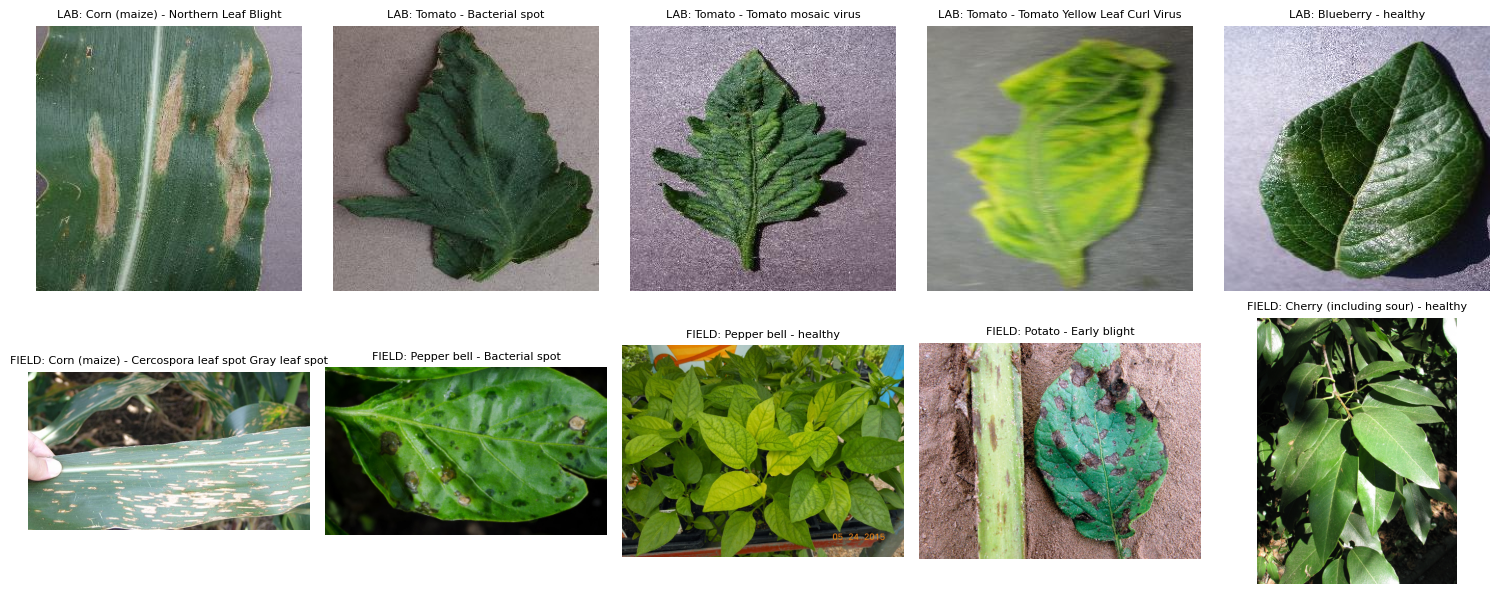

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
lab_examples = random.Random(1).sample(pv_rows, 5)
field_examples = random.Random(1).sample(pd_rows, 5)
for i in range(5):
    axes[0, i].imshow(Image.open(lab_examples[i]["path"]).convert("RGB"))
    axes[0, i].set_title("LAB: " + pretty_class_name(lab_examples[i]["class_name"]), fontsize=8)
    axes[1, i].imshow(Image.open(field_examples[i]["path"]).convert("RGB"))
    axes[1, i].set_title("FIELD: " + pretty_class_name(field_examples[i]["class_name"]), fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 8 — Preparing photos for the network
* **`prepare_image`** (validation, test, field photos — and **the app**): resize the shorter side to 256, cut the
  224 × 224 centre, scale to 0..1, normalise with the ImageNet colours. *(Same code as `src/image_utils.py` in the app.)*
* **`train_transform`** (training photos only): random crop, flips, rotation and colour changes, so the model learns
  the disease and not the exact photo.
* **NEW `replace_background`** (lab training photos, 50 % of the time): finds the leaf with its colour (coloured
  pixels = leaf, grey/white/dark pixels = background), fills holes such as dark lesions, keeps the biggest region, and
  pastes the leaf onto a random crop of a field photo from the PlantDoc **train** part.
* **NEW field training**: a `WeightedRandomSampler` makes about 30 % of every batch field photos (PlantDoc train part).

In [14]:
def resize_shorter_side(image, size):
    """Resize so the SHORTER side becomes `size` pixels, keeping the shape (no stretching)."""
    width, height = image.size
    scale = size / min(width, height)
    new_width = round(width * scale)
    new_height = round(height * scale)
    return image.resize((new_width, new_height), Image.BICUBIC)


def center_crop(image, size):
    """Cut a size x size square out of the middle of the image."""
    width, height = image.size
    left = (width - size) // 2
    top = (height - size) // 2
    return image.crop((left, top, left + size, top + size))


def prepare_image(image):
    """
    PIL image (any size)  ->  numpy array of shape (3, 224, 224), type float32.

    Steps:
      1. make sure it has 3 colour channels (RGB)
      2. resize the shorter side to 256, then cut out the 224 x 224 centre
      3. pixel values 0..255  ->  0..1
      4. normalise each colour: (value - mean) / std   (the pretrained model was trained this way)
      5. change the order from (height, width, colour) to (colour, height, width) — PyTorch/ONNX order
    """
    image = image.convert("RGB")
    image = resize_shorter_side(image, RESIZE_SIZE)
    image = center_crop(image, IMAGE_SIZE)

    pixels = np.asarray(image, dtype=np.float32) / 255.0      # shape (224, 224, 3)
    mean = np.array(IMAGENET_MEAN, dtype=np.float32)
    std = np.array(IMAGENET_STD, dtype=np.float32)
    pixels = (pixels - mean) / std

    pixels = pixels.transpose(2, 0, 1)                         # shape (3, 224, 224)
    return np.ascontiguousarray(pixels, dtype=np.float32)


def load_image(path):
    """Open an image file and return it as an RGB PIL image."""
    with Image.open(path) as image:
        return image.convert("RGB")

In [15]:
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.5, 1.0)),   # random part of the photo, resized to 224
    transforms.RandomHorizontalFlip(),                             # mirror left-right (50% of the time)
    transforms.RandomVerticalFlip(),                               # mirror up-down (50% of the time)
    transforms.RandomRotation(20),                                 # rotate up to 20 degrees
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.03),  # change light / colour
    transforms.ToTensor(),                                         # pixels -> numbers 0..1
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),             # same normalisation as prepare_image
])


def eval_transform(image):
    """Validation / test / field photos: exactly what the app does (see src/image_utils.py)."""
    return torch.from_numpy(prepare_image(image))


class LeafDataset(torch.utils.data.Dataset):
    """A list of rows -> PyTorch dataset. dataset[i] gives (image tensor, label number)."""

    def __init__(self, rows, transform):
        self.rows = rows
        self.transform = transform

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(row["path"]) as image:
            image_tensor = self.transform(image.convert("RGB"))
        return image_tensor, int(row["label"])


def leaf_mask(image):
    # True where the leaf is: coloured (saturation > 0.2) and not too dark
    hsv = np.asarray(image.convert("HSV"), dtype=np.float32) / 255.0
    mask = (hsv[..., 1] > 0.20) & (hsv[..., 2] > 0.10)
    mask = ndimage.binary_opening(mask, iterations=2)            # remove small specks
    mask = ndimage.binary_fill_holes(mask)                       # lesions inside the leaf are leaf too
    labels, count = ndimage.label(mask)                          # keep only the biggest region
    if count > 1:
        sizes = ndimage.sum(mask, labels, range(1, count + 1))
        mask = labels == (np.argmax(sizes) + 1)
    soft_mask = Image.fromarray((mask * 255).astype(np.uint8))
    return soft_mask.filter(ImageFilter.GaussianBlur(2))         # soft edge looks more natural


def replace_background(image, background):
    # random square crop of the background, resized to the photo, slightly blurred like a real out-of-focus background
    width, height = image.size
    side = min(background.size)
    left = random.randint(0, background.size[0] - side)
    top = random.randint(0, background.size[1] - side)
    background = background.crop((left, top, left + side, top + side)).resize((width, height))
    background = background.filter(ImageFilter.GaussianBlur(random.uniform(0, 2)))
    return Image.composite(image, background, leaf_mask(image))


class TrainingDataset(torch.utils.data.Dataset):
    # lab photos sometimes get a field background; field photos are used as they are
    def __init__(self, rows, background_paths):
        self.rows = rows
        self.background_paths = background_paths

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, index):
        row = self.rows[index]
        with Image.open(row["path"]) as image:
            image = image.convert("RGB")
        if (USE_BACKGROUND_SWAP and row["source"] == "lab" and len(self.background_paths) > 0
                and random.random() < BACKGROUND_SWAP_PROB):
            with Image.open(random.choice(self.background_paths)) as background:
                image = replace_background(image, background.convert("RGB"))
        return train_transform(image), int(row["label"])


lab_train_rows = [dict(row, source="lab") for row in pv_rows if row["split"] == "train"]
field_train_rows = [dict(row, source="field") for row in pd_rows if row["field_split"] == "train"]
val_rows = [row for row in pv_rows if row["split"] == "val"]
field_cal_rows = [row for row in pd_rows if row["field_split"] == "cal"]
background_paths = [row["path"] for row in field_train_rows]      # only the TRAIN part, never cal/test

if USE_FIELD_TRAINING:
    train_rows = lab_train_rows + field_train_rows
    # every field photo is picked more often, so that ~30 % of each batch is field photos
    weights = ([(1 - FIELD_SHARE_IN_BATCH) / len(lab_train_rows)] * len(lab_train_rows)
               + [FIELD_SHARE_IN_BATCH / len(field_train_rows)] * len(field_train_rows))
    sampler = torch.utils.data.WeightedRandomSampler(weights, num_samples=len(lab_train_rows), replacement=True)
else:
    train_rows = lab_train_rows
    sampler = None


def make_loader(rows, transform, shuffle):
    dataset = LeafDataset(rows, transform)
    return torch.utils.data.DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, drop_last=shuffle,
                                       num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"))


train_loader = torch.utils.data.DataLoader(TrainingDataset(train_rows, background_paths), batch_size=BATCH_SIZE,
                                           sampler=sampler, shuffle=(sampler is None), drop_last=True,
                                           num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"))
print(f"Lab training photos: {len(lab_train_rows):,} | field training photos: {len(field_train_rows) if USE_FIELD_TRAINING else 0:,}"
      f" | background photos: {len(background_paths):,} | batches per epoch: {len(train_loader)}")

Lab training photos: 38,124 | field training photos: 1,264 | background photos: 1,264 | batches per epoch: 595


### Look at the background swap
Top: original lab photos. Middle: the leaf the code found. Bottom: the same leaf on a field background.

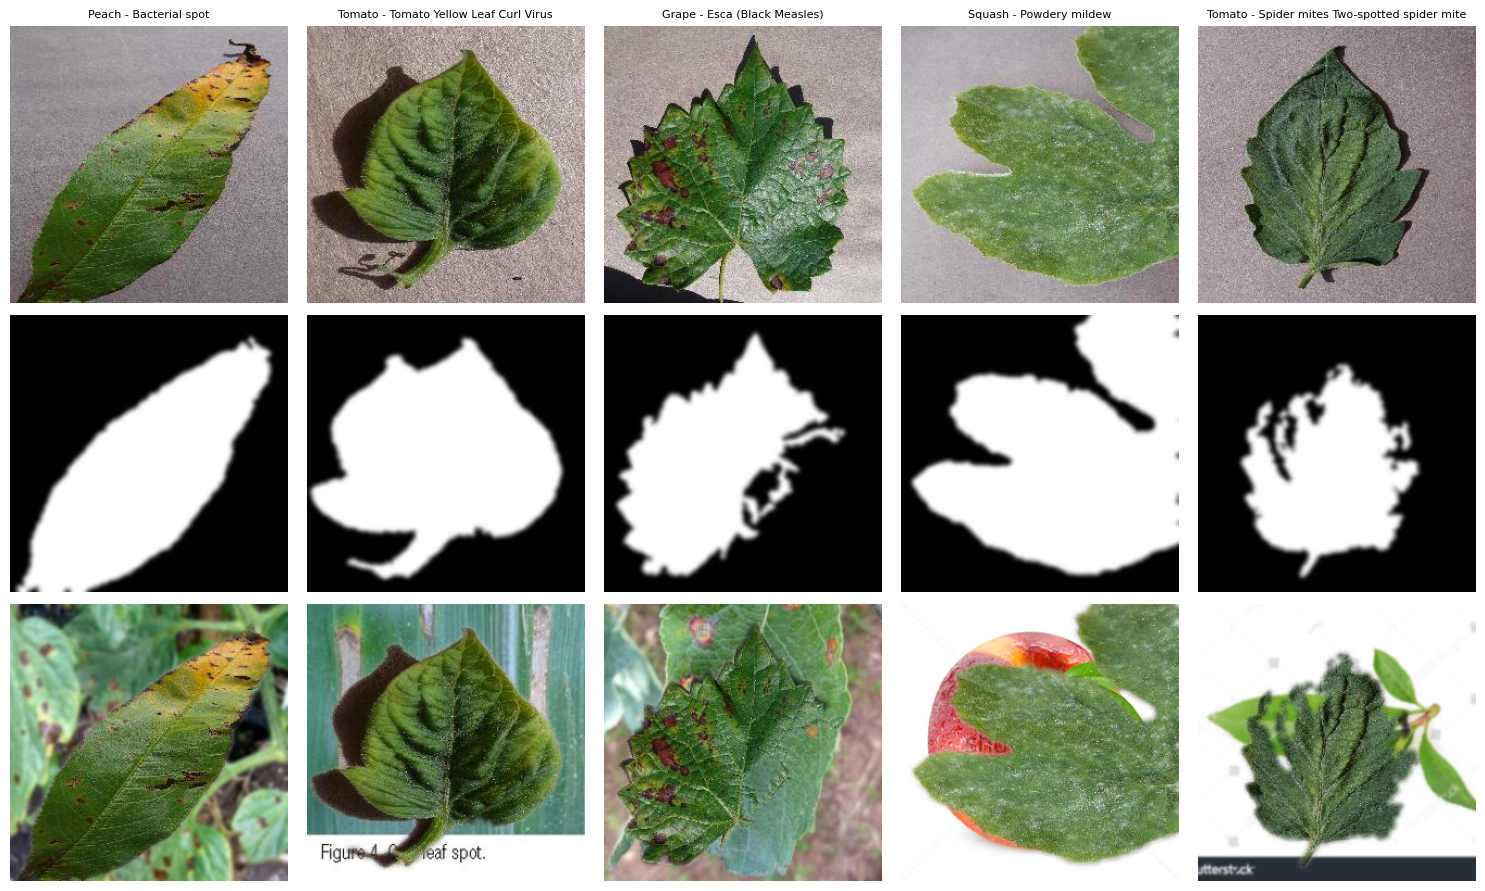

In [16]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
examples = random.Random(3).sample(lab_train_rows, 5)
for i, row in enumerate(examples):
    image = Image.open(row["path"]).convert("RGB")
    background = Image.open(random.Random(i).choice(background_paths)).convert("RGB")
    axes[0, i].imshow(image)
    axes[0, i].set_title(pretty_class_name(row["class_name"]), fontsize=8)
    axes[1, i].imshow(leaf_mask(image), cmap="gray")
    axes[2, i].imshow(replace_background(image, background))
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 9 — Build the model layer by layer
Like `model.add(...)` in Keras:
1. **backbone** — pretrained on ImageNet (1.2 million photos); turns a photo into a list of numbers ("features")
2. **dropout** — during training switches off 20 % of the features at random, so the model does not rely on a few
3. **classifier** — a new layer: one score (logit) for each of our 38 classes

In [17]:
# Layer 1: the pretrained backbone. num_classes=0 removes its old 1000-class ImageNet layer.
backbone = timm.create_model(BACKBONE, pretrained=(PRETRAINED_FILE is None), num_classes=0)
if PRETRAINED_FILE is not None:
    backbone.load_state_dict(torch.load(PRETRAINED_FILE, map_location="cpu"), strict=False)

# How many features per photo? Send one blank photo through the backbone and look.
backbone.eval()
with torch.no_grad():
    num_features = backbone(torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE)).shape[1]

model = nn.Sequential()
model.add_module("backbone", backbone)                                  # layer 1: photo -> features
model.add_module("dropout", nn.Dropout(p=0.2))                           # layer 2: dropout
model.add_module("classifier", nn.Linear(num_features, NUM_CLASSES))     # layer 3: features -> 38 scores
model = model.to(DEVICE)

print(f"Features per photo: {num_features} | {sum(p.numel() for p in model.parameters()) / 1e6:.1f} million parameters | on {DEVICE}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

Features per photo: 1280 | 4.1 million parameters | on cuda


## Step 10 — Training helpers
* **Loss** = cross-entropy with *label smoothing 0.1* (the model is told "95 % sure" instead of "100 %" → less over-confident)
* **Optimizer** = AdamW · **Scheduler** = warm-up, then the learning rate falls smoothly (cosine)
* After every epoch: **macro-F1** on the validation photos; the best weights are kept

In [18]:
def train_one_epoch(optimizer, scheduler, scaler, backbone_frozen):
    model.train()
    if backbone_frozen:
        model.backbone.eval()          # frozen backbone: keep its BatchNorm statistics as they are
    losses = []
    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)
        with torch.autocast(device_type="cuda", enabled=USE_AMP):
            outputs = model(images)
            loss = F.cross_entropy(outputs, labels, label_smoothing=LABEL_SMOOTHING)
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        losses.append(loss.item())
    return float(np.mean(losses))


def predict_logits(rows):
    # runs the model on a list of photos -> logits (photos x 38) as numpy
    model.eval()
    all_logits = []
    with torch.no_grad():
        for images, _ in make_loader(rows, eval_transform, shuffle=False):
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                logits = model(images.to(DEVICE))
            all_logits.append(logits.float().cpu().numpy())
    return np.concatenate(all_logits)


def field_accuracy():
    # accuracy on the field "cal" part - only printed so you can watch field progress, not used to pick the epoch
    predictions = predict_logits(field_cal_rows).argmax(axis=1)
    return float(np.mean(predictions == np.array([row["label"] for row in field_cal_rows])))


def validation_f1():
    predictions = predict_logits(val_rows).argmax(axis=1)
    labels = [row["label"] for row in val_rows]
    return f1_score(labels, predictions, average="macro")


def make_scheduler(optimizer, epochs, warmup_epochs):
    total_steps = epochs * len(train_loader)
    if warmup_epochs == 0:
        return torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=total_steps)
    warmup_steps = warmup_epochs * len(train_loader)
    warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=1 / warmup_steps, total_iters=warmup_steps)
    cosine = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(1, total_steps - warmup_steps))
    return torch.optim.lr_scheduler.SequentialLR(optimizer, [warmup, cosine], milestones=[warmup_steps])


history = []        # one line per epoch
best_f1 = -1.0
best_weights = None

## Step 11 — Stage 1: train only the new last layer
The pretrained backbone is **frozen**; only `model.classifier` learns.

In [19]:
for p in model.parameters():
    p.requires_grad = False
for p in model.classifier.parameters():
    p.requires_grad = True

optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=LR_STAGE1, weight_decay=WEIGHT_DECAY)
scheduler = make_scheduler(optimizer, HEAD_EPOCHS, warmup_epochs=0)
scaler = torch.amp.GradScaler(enabled=USE_AMP)

for epoch in range(HEAD_EPOCHS):
    start = time.time()
    loss = train_one_epoch(optimizer, scheduler, scaler, backbone_frozen=True)
    f1 = validation_f1()
    field_acc = field_accuracy()
    history.append({"stage": 1, "epoch": epoch + 1, "loss": loss, "val_f1": f1, "field_cal_acc": field_acc})
    print(f"[stage 1] epoch {epoch + 1}/{HEAD_EPOCHS}  loss {loss:.4f}  lab val macro-F1 {f1:.4f}  field acc {field_acc:.1%}  ({time.time() - start:.0f} s)")
    if f1 > best_f1:
        best_f1 = f1
        best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

[stage 1] epoch 1/2  loss 1.8790  lab val macro-F1 0.7990  field acc 54.5%  (1027 s)
[stage 1] epoch 2/2  loss 1.5639  lab val macro-F1 0.8192  field acc 54.9%  (1034 s)


## Step 12 — Stage 2: fine-tune the whole network
Everything learns now, but the pretrained layers get a **10× smaller learning rate**. Skipped if `FINETUNE_EPOCHS = 0`.

In [20]:
if FINETUNE_EPOCHS > 0:
    for p in model.parameters():
        p.requires_grad = True

    optimizer = torch.optim.AdamW([
        {"params": model.backbone.parameters(), "lr": LR_BACKBONE},
        {"params": model.classifier.parameters(), "lr": LR_HEAD},
    ], weight_decay=WEIGHT_DECAY)
    scheduler = make_scheduler(optimizer, FINETUNE_EPOCHS, warmup_epochs=1)
    scaler = torch.amp.GradScaler(enabled=USE_AMP)

    epochs_without_improvement = 0
    for epoch in range(FINETUNE_EPOCHS):
        start = time.time()
        loss = train_one_epoch(optimizer, scheduler, scaler, backbone_frozen=False)
        f1 = validation_f1()
        field_acc = field_accuracy()
        history.append({"stage": 2, "epoch": epoch + 1, "loss": loss, "val_f1": f1, "field_cal_acc": field_acc})
        print(f"[stage 2] epoch {epoch + 1}/{FINETUNE_EPOCHS}  loss {loss:.4f}  lab val macro-F1 {f1:.4f}  field acc {field_acc:.1%}  ({time.time() - start:.0f} s)")
        if f1 > best_f1:
            best_f1 = f1
            best_weights = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= PATIENCE:
                print("Stopping early: validation F1 stopped improving.")
                break

model.load_state_dict(best_weights)       # keep the best epoch
print(f"Best validation macro-F1: {best_f1:.4f}")

[stage 2] epoch 1/8  loss 1.8821  lab val macro-F1 0.8179  field acc 55.3%  (1079 s)
[stage 2] epoch 2/8  loss 1.2586  lab val macro-F1 0.9071  field acc 60.4%  (1067 s)
[stage 2] epoch 3/8  loss 1.0908  lab val macro-F1 0.9269  field acc 60.8%  (1075 s)
[stage 2] epoch 4/8  loss 1.0083  lab val macro-F1 0.9428  field acc 61.8%  (1082 s)
[stage 2] epoch 5/8  loss 0.9618  lab val macro-F1 0.9453  field acc 62.2%  (1056 s)
[stage 2] epoch 6/8  loss 0.9359  lab val macro-F1 0.9532  field acc 62.6%  (1092 s)
[stage 2] epoch 7/8  loss 0.9246  lab val macro-F1 0.9535  field acc 64.4%  (1077 s)
[stage 2] epoch 8/8  loss 0.9261  lab val macro-F1 0.9517  field acc 62.8%  (1083 s)
Best validation macro-F1: 0.9535


## Step 13 — Run the model once on every photo
All the next steps only need the model's **logits**, so we compute them once.

In [21]:
start = time.time()
logits_pv = predict_logits(pv_rows)
logits_pd = predict_logits(pd_rows)
logits_rice = predict_logits(rice_rows)
print(f"Done in {time.time() - start:.0f} s")

pv_labels = np.array([row["label"] for row in pv_rows])
pv_split = np.array([row["split"] for row in pv_rows])
pd_labels = np.array([row["label"] for row in pd_rows])
pd_dup = np.array([row["dup_group"] for row in pd_rows])
is_val, is_cal, is_test = pv_split == "val", pv_split == "cal", pv_split == "test"
pd_part = np.array([row["field_split"] for row in pd_rows])
is_ftrain, is_fcal, is_ftest = pd_part == "train", pd_part == "cal", pd_part == "test"
print(f"Field photos: train {is_ftrain.sum()} | cal {is_fcal.sum()} | test {is_ftest.sum()}")

Done in 213 s
Field photos: train 1264 | cal 508 | test 742


## Step 14 — The maths of our method (conformal prediction over action groups)
*(The functions marked "app" are the same as `src/conformal.py` in the app.)*

| Function | What it does |
|---|---|
| `softmax` (app) | logits → probabilities, divided by a temperature *T* |
| `fit_temperature` | tries many *T*, keeps the one with the lowest negative log-likelihood on val photos |
| `group_probabilities` (app) | probability of a group = sum of its classes' probabilities |
| `group_scores` (app) | **s(x, g) = 1 − group probability** (small = likely) |
| `conformal_quantile` | the ⌈(n+1)(1−α)⌉-th smallest score |
| `calibrate_group_thresholds` | one threshold **per group** (Mondrian) from calibration photos |
| `prediction_sets` (app) | groups with s(x, g) ≤ threshold |
| `energy_score` (app) | E = −T·log Σ exp(z/T): high = unfamiliar photo |
| `decide` (app) | 1 group → advise · 2+ → refer to KVK · 0 or unfamiliar → unknown |
| `top1_sets`, `aps_*` | the two methods we compare against |

In [22]:
def softmax(logits, temperature=1.0):
    """logits (photos x classes) -> probabilities (photos x classes), each row adds up to 1."""
    scaled = np.asarray(logits, dtype=np.float64) / temperature
    scaled = scaled - scaled.max(axis=1, keepdims=True)    # subtract the biggest value: avoids overflow
    exp_values = np.exp(scaled)
    return exp_values / exp_values.sum(axis=1, keepdims=True)


def negative_log_likelihood(logits, labels, temperature):
    """Average of -log(probability of the correct class). Lower = better calibrated."""
    probs = softmax(logits, temperature)
    correct_probs = probs[np.arange(len(labels)), labels]
    return float(np.mean(-np.log(correct_probs + 1e-12)))


def fit_temperature(logits, labels):
    """Try many temperatures and keep the one with the lowest negative log-likelihood.
    (A simple 'grid search': no clever maths needed.)"""
    best_temperature = 1.0
    best_loss = negative_log_likelihood(logits, labels, 1.0)
    for temperature in np.arange(0.05, 5.0, 0.01):
        loss = negative_log_likelihood(logits, labels, temperature)
        if loss < best_loss:
            best_loss = loss
            best_temperature = float(temperature)
    return best_temperature


def group_probabilities(probs, class_groups, num_groups):
    """probs (photos x 38 classes) -> group probabilities (photos x 6 groups)."""
    class_groups = np.asarray(class_groups)
    result = np.zeros((len(probs), num_groups))
    for g in range(num_groups):
        result[:, g] = probs[:, class_groups == g].sum(axis=1)
    return result


def group_scores(probs, class_groups, num_groups):
    """s(x, g) = 1 - group probability.  Small score = this group is likely."""
    return 1.0 - group_probabilities(probs, class_groups, num_groups)


def conformal_quantile(scores, alpha):
    """The ceil((n + 1) * (1 - alpha))-th smallest score.
    This small '+1' is what makes the 90% promise exact. Returns infinity if there are too few scores."""
    n = len(scores)
    k = math.ceil((n + 1) * (1 - alpha))
    if n == 0 or k > n:
        return math.inf
    sorted_scores = np.sort(scores)
    return float(sorted_scores[k - 1])


def calibrate_group_thresholds(probs, labels, class_groups, num_groups, alpha, fallback=None):
    """
    'Mondrian' calibration = a separate threshold for every group, using only the calibration
    photos whose TRUE group is that group. So rare groups get their own 90% promise too.

    If a group has too few calibration photos and `fallback` thresholds are given,
    that group keeps its fallback threshold.
    """
    class_groups = np.asarray(class_groups)
    true_groups = class_groups[labels]
    scores = group_scores(probs, class_groups, num_groups)
    score_of_true_group = scores[np.arange(len(labels)), true_groups]

    minimum_photos = math.ceil(1 / alpha) - 1          # with fewer photos the quantile is infinite
    thresholds = np.zeros(num_groups)
    for g in range(num_groups):
        scores_of_group = score_of_true_group[true_groups == g]
        if len(scores_of_group) < minimum_photos and fallback is not None:
            thresholds[g] = fallback[g]
        else:
            thresholds[g] = conformal_quantile(scores_of_group, alpha)
    return thresholds


def prediction_sets(probs, class_groups, num_groups, thresholds):
    """True/False table (photos x groups): is group g in the prediction set of photo i?"""
    scores = group_scores(probs, class_groups, num_groups)
    return scores <= np.asarray(thresholds)


def energy_score(logits, temperature=1.0):
    """Energy = -T * log(sum(exp(logits / T))).
    LOW for photos that look like the training photos, HIGH for unfamiliar photos."""
    scaled = np.asarray(logits, dtype=np.float64) / temperature
    biggest = scaled.max(axis=1, keepdims=True)
    log_sum_exp = biggest[:, 0] + np.log(np.exp(scaled - biggest).sum(axis=1))
    return -temperature * log_sum_exp


def decide(groups_in_set, is_unfamiliar=False):
    """
    groups_in_set: list of group numbers in the prediction set of ONE photo.
    Returns ("advise", group) or ("refer", None) or ("unknown", None).
    """
    if is_unfamiliar or len(groups_in_set) == 0:
        return "unknown", None
    if len(groups_in_set) == 1:
        return "advise", groups_in_set[0]
    return "refer", None


def top1_sets(probs, class_groups, num_groups):
    """Normal classifier: always exactly the group of the most likely class."""
    class_groups = np.asarray(class_groups)
    sets = np.zeros((len(probs), num_groups), dtype=bool)
    best_class = probs.argmax(axis=1)
    sets[np.arange(len(probs)), class_groups[best_class]] = True
    return sets


def aps_scores(probs):
    """APS (standard conformal method on CLASSES): score of a class = total probability of all
    classes ranked at or above it."""
    scores = np.zeros_like(probs)
    for i in range(len(probs)):
        order = np.argsort(-probs[i])                    # most likely class first
        scores[i][order] = np.cumsum(probs[i][order])
    return scores


def calibrate_aps(probs, labels, alpha):
    scores = aps_scores(probs)
    return conformal_quantile(scores[np.arange(len(labels)), labels], alpha)


def aps_group_sets(probs, class_groups, num_groups, threshold):
    """APS set of classes -> set of groups (a group is in if any of its classes is in)."""
    class_groups = np.asarray(class_groups)
    class_sets = aps_scores(probs) <= threshold
    for i in range(len(probs)):
        if not class_sets[i].any():                      # never return an empty set
            class_sets[i, probs[i].argmax()] = True
    sets = np.zeros((len(probs), num_groups), dtype=bool)
    for g in range(num_groups):
        sets[:, g] = class_sets[:, class_groups == g].any(axis=1)
    return sets

**Metrics:** *coverage* (true group inside the set, target ≥ 0.90) · *set size* · *advice rate* (exactly one group) ·
**IAR** = wrong advice / all advice given (our safety metric) · *ECE* (gap between confidence and accuracy).

In [23]:
def advisory_metrics(sets, labels, class_groups, group_codes):
    """sets: True/False table (photos x groups). labels: true class number of every photo."""
    class_groups = np.asarray(class_groups)
    true_groups = class_groups[labels]
    set_size = sets.sum(axis=1)
    advised = set_size == 1                        # exactly one group -> advice is given
    advised_group = sets.argmax(axis=1)            # (only meaningful when advised)
    wrong_advice = advised & (advised_group != true_groups)

    result = {
        "coverage": float(sets[np.arange(len(labels)), true_groups].mean()),
        "set_size": float(set_size.mean()),
        "advice_rate": float(advised.mean()),
        "IAR": float(wrong_advice.sum() / max(advised.sum(), 1)),
        "wrong_advice_all": float(wrong_advice.mean()),
    }
    # coverage of every group separately (NaN if there is no photo of that group)
    for g, code in enumerate(group_codes):
        photos_of_group = true_groups == g
        if photos_of_group.any():
            result[f"coverage_{code}"] = float(sets[photos_of_group, g].mean())
        else:
            result[f"coverage_{code}"] = float("nan")
    return result


def expected_calibration_error(probs, labels, number_of_bins=15):
    """Put photos in bins by confidence; compare each bin's confidence with its accuracy."""
    confidence = probs.max(axis=1)
    correct = (probs.argmax(axis=1) == labels).astype(float)
    bin_edges = np.linspace(0, 1, number_of_bins + 1)
    ece = 0.0
    for b in range(number_of_bins):
        in_bin = (confidence > bin_edges[b]) & (confidence <= bin_edges[b + 1])
        if in_bin.any():
            gap = abs(correct[in_bin].mean() - confidence[in_bin].mean())
            ece += in_bin.mean() * gap
    return float(ece)

## Step 15 — Accuracy and temperature scaling
All **field** numbers from now on use only the PlantDoc **test** part — photos never used for training or thresholds.

In [24]:
T = fit_temperature(logits_pv[is_val], pv_labels[is_val])
probs_pv = softmax(logits_pv, T)
probs_pd = softmax(logits_pd, T)

lab_pred = probs_pv[is_test].argmax(axis=1)
field_true = pd_labels[is_ftest]
field_pred = probs_pd[is_ftest].argmax(axis=1)

scores = {
    "temperature": T,
    "lab_accuracy": float(np.mean(lab_pred == pv_labels[is_test])),
    "lab_macro_f1": float(f1_score(pv_labels[is_test], lab_pred, average="macro")),
    "field_accuracy": float(np.mean(field_pred == field_true)),
    "field_macro_f1": float(f1_score(field_true, field_pred, average="macro", labels=sorted(set(field_true)))),
    "field_group_accuracy": float(np.mean(CLASS_GROUPS[field_pred] == CLASS_GROUPS[field_true])),
    "field_mean_confidence": float(probs_pd[is_ftest].max(axis=1).mean()),
    "lab_ece": expected_calibration_error(probs_pv[is_test], pv_labels[is_test]),
    "field_ece": expected_calibration_error(probs_pd[is_ftest], field_true),
}
print("Switches -> background swap:", USE_BACKGROUND_SWAP, "| field training:", USE_FIELD_TRAINING)
pd.Series(scores).round(4)

Switches -> background swap: True | field training: True


,0
temperature,0.4700
lab_accuracy,0.9760
lab_macro_f1,0.9701
field_accuracy,0.6388
field_macro_f1,0.6188
field_group_accuracy,0.8154
field_mean_confidence,0.8358
lab_ece,0.0055
field_ece,0.1994


Compare **field accuracy** across runs with different switches (same field test part, same seed) — that comparison is the result for the paper.

## Step 16 — Our method vs Top-1 and APS, on lab and field photos
Thresholds learned on **lab** calibration photos, tested on lab test photos and on the field **test** part.

In [25]:
def calibrate(probs, labels, fallback=None):
    fallback_thresholds = None if fallback is None else fallback["group_thresholds"]
    return {
        "group_thresholds": calibrate_group_thresholds(probs, labels, CLASS_GROUPS, NUM_GROUPS, ALPHA, fallback_thresholds),
        "aps_threshold": calibrate_aps(probs, labels, ALPHA),
    }


def evaluate(calibration, probs, labels):
    sets = {
        "Top-1": top1_sets(probs, CLASS_GROUPS, NUM_GROUPS),
        "APS → groups": aps_group_sets(probs, CLASS_GROUPS, NUM_GROUPS, calibration["aps_threshold"]),
        "Action-group (ours)": prediction_sets(probs, CLASS_GROUPS, NUM_GROUPS, calibration["group_thresholds"]),
    }
    return {method: advisory_metrics(s, labels, CLASS_GROUPS, GROUP_CODES) for method, s in sets.items()}


lab_calibration = calibrate(probs_pv[is_cal], pv_labels[is_cal])
results_lab = evaluate(lab_calibration, probs_pv[is_test], pv_labels[is_test])
results_field_lab_thresholds = evaluate(lab_calibration, probs_pd[is_ftest], pd_labels[is_ftest])

pd.concat({"lab → lab test": pd.DataFrame(results_lab).T,
           "lab → FIELD test": pd.DataFrame(results_field_lab_thresholds).T}).round(3)

coverage  set_size  advice_rate    IAR  \
lab → lab test   Top-1                   0.986     1.000        1.000  0.014   
                 APS → groups            1.000     3.471        0.209  0.000   
                 Action-group (ours)     0.907     0.910        0.910  0.003   
lab → FIELD test Top-1                   0.815     1.000        1.000  0.185   
                 APS → groups            0.997     4.031        0.124  0.022   
                 Action-group (ours)     0.540     0.584        0.584  0.074   

                                      wrong_advice_all  coverage_G0  \
lab → lab test   Top-1                           0.014        0.999   
                 APS → groups                    0.000        1.000   
                 Action-group (ours)             0.003        0.899   
lab → FIELD test Top-1                           0.185        0.932   
                 APS → groups                    0.003        1.000   
                 Action-group (ours)             0.043        0.520   

                                      coverage_G1  coverage_G2  coverage_G3  \
lab → lab test   Top-1                      0.980        0.966        0.979   
                 APS → groups               1.000        1.000        1.000   
                 Action-group (ours)        0.919        0.917        0.909   
lab → FIELD test Top-1                      0.831        0.695        0.377   
                 APS → groups               0.997        0.983        1.000   
                 Action-group (ours)        0.612        0.593        0.245   

                                      coverage_G4  coverage_G5  
lab → lab test   Top-1                      0.987        0.976  
                 APS → groups               1.000        1.000  
                 Action-group (ours)        0.887        0.976  
lab → FIELD test Top-1                      0.703          NaN  
                 APS → groups               1.000          NaN  
                 Action-group (ours)        0.351          NaN

## Step 17 — Field re-calibration: how many field photos are needed?
Take **n labelled field photos per group** from the **cal** part, recompute only the thresholds, test on the **test**
part; repeat with different photos and average. (A group with fewer cal photos than n uses all it has.)

In [26]:
pd_groups = CLASS_GROUPS[pd_labels]


def pick_field_calibration_photos(n_per_group, seed):
    # True = chosen calibration photo (always from the cal part)
    rng = np.random.default_rng(seed)
    chosen = []
    for g in sorted(set(pd_groups[is_fcal])):
        dup_groups = sorted(set(pd_dup[is_fcal & (pd_groups == g)]))
        rng.shuffle(dup_groups)
        picked = 0
        for dup_group in dup_groups:
            if picked >= n_per_group:
                break
            indices = np.nonzero(is_fcal & (pd_dup == dup_group))[0]
            chosen.extend(indices.tolist())
            picked += len(indices)
    mask = np.zeros(len(pd_labels), dtype=bool)
    mask[chosen] = True
    return mask


recalibration_results = {}
for n in RECAL_N:
    runs = []
    for repeat in range(REPEATS):
        cal_mask = pick_field_calibration_photos(n, seed=1000 * n + repeat)
        field_calibration = calibrate(probs_pd[cal_mask], pd_labels[cal_mask], fallback=lab_calibration)
        runs.append(evaluate(field_calibration, probs_pd[is_ftest], pd_labels[is_ftest]))
    recalibration_results[n] = {method: {metric: float(np.nanmean([run[method][metric] for run in runs]))
                                         for metric in runs[0][method]} for method in runs[0]}

pd.concat({f"n = {n}": pd.DataFrame(v).T for n, v in recalibration_results.items()}).round(3)

/tmp/ipykernel_394/3931596019.py:30: RuntimeWarning: Mean of empty slice
  recalibration_results[n] = {method: {metric: float(np.nanmean([run[method][metric] for run in runs]))


coverage  set_size  advice_rate    IAR  \
n = 10 Top-1                   0.815     1.000        1.000  0.185   
       APS → groups            0.992     3.545        0.210  0.026   
       Action-group (ours)     0.937     2.035        0.329  0.048   
n = 25 Top-1                   0.815     1.000        1.000  0.185   
       APS → groups            0.995     3.735        0.175  0.023   
       Action-group (ours)     0.927     1.984        0.336  0.042   
n = 50 Top-1                   0.815     1.000        1.000  0.185   
       APS → groups            0.996     3.726        0.172  0.021   
       Action-group (ours)     0.906     1.734        0.451  0.065   

                            wrong_advice_all  coverage_G0  coverage_G1  \
n = 10 Top-1                           0.185        0.932        0.831   
       APS → groups                    0.006        1.000        0.994   
       Action-group (ours)             0.017        0.930        0.947   
n = 25 Top-1                           0.185        0.932        0.831   
       APS → groups                    0.004        1.000        0.995   
       Action-group (ours)             0.014        0.884        0.945   
n = 50 Top-1                           0.185        0.932        0.831   
       APS → groups                    0.004        1.000        0.996   
       Action-group (ours)             0.030        0.871        0.912   

                            coverage_G2  coverage_G3  coverage_G4  coverage_G5  
n = 10 Top-1                      0.695        0.377        0.703          NaN  
       APS → groups               0.972        0.957        1.000          NaN  
       Action-group (ours)        0.941        0.951        0.855          NaN  
n = 25 Top-1                      0.695        0.377        0.703          NaN  
       APS → groups               0.979        0.980        1.000          NaN  
       Action-group (ours)        0.989        0.978        0.889          NaN  
n = 50 Top-1                      0.695        0.377        0.703          NaN  
       APS → groups               0.981        0.992        1.000          NaN  
       Action-group (ours)        0.983        0.962        0.892          NaN

## Step 18 — Final thresholds for the app + the "unknown photo" limit
* App thresholds come from **all** photos of the field **cal** part.
* Energy limit = 95th percentile of the energy of those photos; above it the app says "photo not recognised".
* The final system is tested on the field **test** part.

In [27]:
final_calibration = calibrate(probs_pd[is_fcal], pd_labels[is_fcal], fallback=lab_calibration)
group_thresholds = np.minimum(final_calibration["group_thresholds"], 1.0)    # a score is never above 1
energy_threshold = float(np.quantile(energy_score(logits_pd[is_fcal], T), 0.95))

final_results = evaluate(final_calibration, probs_pd[is_ftest], pd_labels[is_ftest])

energy_lab = energy_score(logits_pv[is_test], T)
energy_rice = energy_score(logits_rice, T)
unknown_results = {
    "energy_threshold": energy_threshold,
    "rice_flagged_unknown": float(np.mean(energy_rice > energy_threshold)),
    "field_test_flagged_unknown": float(np.mean(energy_score(logits_pd[is_ftest], T) > energy_threshold)),
    "lab_test_flagged_unknown": float(np.mean(energy_lab > energy_threshold)),
    "auroc_lab_vs_rice": float(roc_auc_score(np.r_[np.ones(len(energy_rice)), np.zeros(len(energy_lab))],
                                             np.r_[energy_rice, energy_lab])),
}
print("Thresholds per group:", {GROUP_CODES[g]: round(float(group_thresholds[g]), 4) for g in range(NUM_GROUPS)})
display(pd.Series(unknown_results).round(3))
pd.DataFrame(final_results).T.round(3)

Thresholds per group: {'G0': 0.1234, 'G1': 0.8968, 'G2': 0.9969, 'G3': 0.9999, 'G4': 0.9543, 'G5': 0.5403}


,0
energy_threshold,0.480
rice_flagged_unknown,0.000
field_test_flagged_unknown,0.038
lab_test_flagged_unknown,0.000
auroc_lab_vs_rice,0.887


,coverage,set_size,advice_rate,IAR,wrong_advice_all,coverage_G0,coverage_G1,coverage_G2,coverage_G3,coverage_G4,coverage_G5
Top-1,0.815,1.000,1.000,0.185,0.185,0.932,0.831,0.695,0.377,0.703,NaN
APS → groups,0.996,3.674,0.179,0.023,0.004,1.000,0.994,0.983,1.000,1.000,NaN
Action-group (ours),0.910,1.743,0.446,0.057,0.026,0.852,0.933,0.983,0.962,0.892,NaN


## Step 19 — Figures

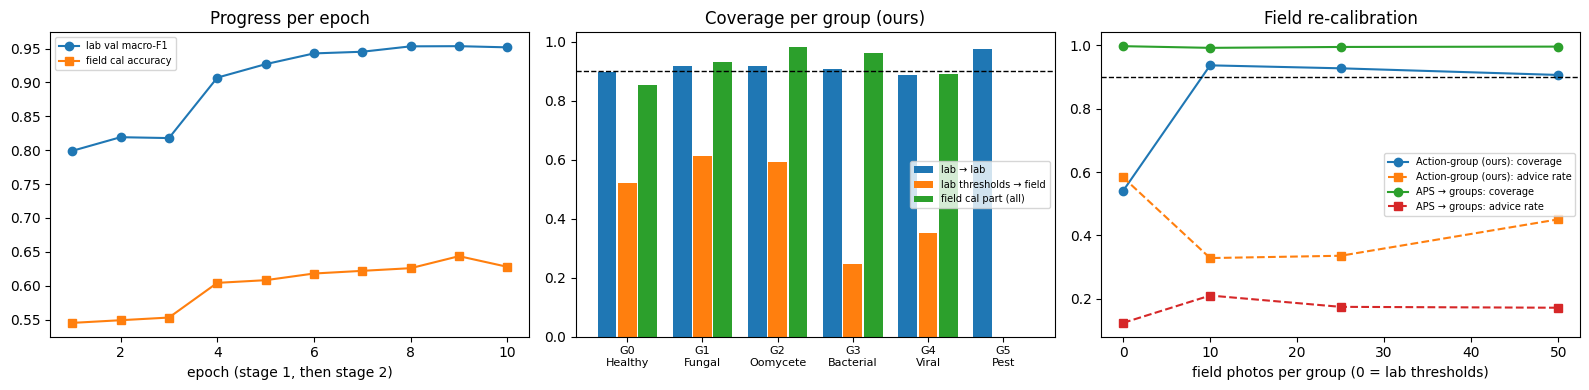

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(range(1, len(history) + 1), [h["val_f1"] for h in history], "-o", label="lab val macro-F1")
axes[0].plot(range(1, len(history) + 1), [h["field_cal_acc"] for h in history], "-s", label="field cal accuracy")
axes[0].set_title("Progress per epoch")
axes[0].legend(fontsize=7)
axes[0].set_xlabel("epoch (stage 1, then stage 2)")

group_labels = [f"{c}\n{GROUP_NAMES[c].split(' ')[0]}" for c in GROUP_CODES]
bars = [("lab → lab", results_lab), ("lab thresholds → field", results_field_lab_thresholds),
        ("field cal part (all)", final_results)]
for k, (label, result) in enumerate(bars):
    heights = [result["Action-group (ours)"][f"coverage_{c}"] for c in GROUP_CODES]
    axes[1].bar(np.arange(NUM_GROUPS) + (k - 1) * 0.27, np.nan_to_num(heights), 0.25, label=label)
axes[1].axhline(1 - ALPHA, color="black", linestyle="--", linewidth=1)
axes[1].set_xticks(range(NUM_GROUPS))
axes[1].set_xticklabels(group_labels, fontsize=8)
axes[1].set_title("Coverage per group (ours)")
axes[1].legend(fontsize=7)

x_values = [0] + RECAL_N
for method in ["Action-group (ours)", "APS → groups"]:
    coverage = [results_field_lab_thresholds[method]["coverage"]] + [recalibration_results[n][method]["coverage"] for n in RECAL_N]
    advice = [results_field_lab_thresholds[method]["advice_rate"]] + [recalibration_results[n][method]["advice_rate"] for n in RECAL_N]
    axes[2].plot(x_values, coverage, "-o", label=method + ": coverage")
    axes[2].plot(x_values, advice, "--s", label=method + ": advice rate")
axes[2].axhline(1 - ALPHA, color="black", linestyle="--", linewidth=1)
axes[2].set_xlabel("field photos per group (0 = lab thresholds)")
axes[2].set_title("Field re-calibration")
axes[2].legend(fontsize=7)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "results.png", dpi=150)
plt.show()

## Step 20 — SAVE the model
* `plant_model.onnx` — the network in ONNX format: the app runs it with `onnxruntime`, **no PyTorch needed** on your computer
* `model_info.json` — everything else the app needs (class names, groups, temperature, thresholds, energy limit, scores)
* `plant_model.pt` — PyTorch weights, only to train further later

In [29]:
model_cpu = model.to("cpu").float().eval()
torch.save({"backbone": BACKBONE, "state_dict": model_cpu.state_dict(), "class_names": CLASS_NAMES},
           OUTPUT_DIR / "plant_model.pt")

example_photo = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE)
export_settings = dict(input_names=["image"], output_names=["logits"],
                       dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}}, opset_version=17)
try:
    torch.onnx.export(model_cpu, example_photo, MODEL_FILE, dynamo=False, **export_settings)
except TypeError:                     # older PyTorch has no `dynamo` option
    torch.onnx.export(model_cpu, example_photo, MODEL_FILE, **export_settings)

model_info = {
    "backbone": BACKBONE,
    "trained_on": str(date.today()),
    "quick_test": QUICK_TEST,
    "finetuned": FINETUNE_EPOCHS > 0,
    "background_swap": USE_BACKGROUND_SWAP,
    "field_training": USE_FIELD_TRAINING,
    "class_names": CLASS_NAMES,
    "class_groups": CLASS_GROUPS.tolist(),
    "group_codes": GROUP_CODES,
    "temperature": T,
    "alpha": ALPHA,
    "group_thresholds": [float(x) for x in group_thresholds],
    "group_thresholds_lab": [float(min(x, 1.0)) for x in lab_calibration["group_thresholds"]],
    "energy_threshold": energy_threshold,
    "image_size": IMAGE_SIZE,
    "resize_size": RESIZE_SIZE,
    "scores": {**scores,
               "field_coverage": final_results["Action-group (ours)"]["coverage"],
               "field_advice_rate": final_results["Action-group (ours)"]["advice_rate"],
               "field_IAR": final_results["Action-group (ours)"]["IAR"],
               "field_IAR_top1": final_results["Top-1"]["IAR"]},
}
with open(MODEL_INFO_FILE, "w") as file:
    json.dump(model_info, file, indent=1)


def to_plain(value):
    # numpy numbers and NaN -> normal Python values that JSON accepts
    if isinstance(value, dict):
        return {str(k): to_plain(v) for k, v in value.items()}
    if isinstance(value, list):
        return [to_plain(v) for v in value]
    if isinstance(value, (str, bool)) or value is None:
        return value
    number = float(value)
    return None if math.isnan(number) else number


all_results = {"settings": {"backbone": BACKBONE, "quick_test": QUICK_TEST, "head_epochs": HEAD_EPOCHS,
                            "finetune_epochs": FINETUNE_EPOCHS, "seed": SEED, "alpha": ALPHA,
                            "background_swap": USE_BACKGROUND_SWAP, "background_swap_prob": BACKGROUND_SWAP_PROB,
                            "field_training": USE_FIELD_TRAINING, "field_share_in_batch": FIELD_SHARE_IN_BATCH,
                            "field_split": FIELD_SPLIT},
               "history": history, "scores": scores,
               "lab_to_lab": results_lab, "lab_thresholds_to_field": results_field_lab_thresholds,
               "field_recalibration": recalibration_results, "final_system_field_test": final_results,
               "unknown_photo_gate": unknown_results}
with open(OUTPUT_DIR / "results.json", "w") as file:
    json.dump(to_plain(all_results), file, indent=1)

for path in sorted(OUTPUT_DIR.iterdir()):
    print(f"{path.name:28s} {path.stat().st_size / 1e6:6.1f} MB")

/tmp/ipykernel_394/2165647606.py:9: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model_cpu, example_photo, MODEL_FILE, dynamo=False, **export_settings)


model_info.json                 0.0 MB
photos_plantdoc.csv             0.4 MB
photos_plantvillage.csv        10.8 MB
plant_model.onnx               16.2 MB
plant_model.pt                 16.5 MB
results.json                    0.0 MB
results.png                     0.1 MB


## Step 21 — Test the saved model exactly like the app will
This cell does what `src/predictor.py` does on your computer: load the **ONNX file** and `model_info.json`, prepare a
field photo with `prepare_image`, and decide. It also checks that ONNX and PyTorch give the same numbers.

In [30]:
info = json.load(open(MODEL_INFO_FILE))
session = onnxruntime.InferenceSession(str(MODEL_FILE), providers=["CPUExecutionProvider"])

test_row = next(row for row in pd_rows if row["field_split"] == "test")
photo = load_image(test_row["path"])
pixels = prepare_image(photo)[np.newaxis]                         # (1, 3, 224, 224)
onnx_logits = session.run(None, {"image": pixels})[0]
with torch.no_grad():
    torch_logits = model_cpu(torch.from_numpy(pixels)).numpy()
print(f"largest difference ONNX vs PyTorch: {np.abs(onnx_logits - torch_logits).max():.1e}  (should be < 1e-3)")

probs = softmax(onnx_logits, info["temperature"])
in_set = prediction_sets(probs, info["class_groups"], NUM_GROUPS, info["group_thresholds"])[0]
is_unfamiliar = energy_score(onnx_logits, info["temperature"])[0] > info["energy_threshold"]
decision, group = decide([g for g in range(NUM_GROUPS) if in_set[g]], is_unfamiliar)

print("true class    :", pretty_class_name(test_row["class_name"]))
print("model's guess :", pretty_class_name(info["class_names"][probs[0].argmax()]), f"({probs[0].max():.0%})")
print("decision      :", decision, "" if group is None else "-> " + GROUP_NAMES[GROUP_CODES[group]])

largest difference ONNX vs PyTorch: 6.7e-06  (should be < 1e-3)
true class    : Apple - Apple scab
model's guess : Apple - Apple scab (98%)
decision      : advise -> Fungal


## Step 22 — Download `trained_model.zip`
Then on your computer: unzip it **into** `plant_disease_advisor\saved_model\` (replace the old files) and run
`streamlit run app/streamlit_app.py`. If the download does not start, open the 📁 *Files* panel on the left and
download `trained_model.zip` from there (right-click → Download).

In [31]:
zip_path = shutil.make_archive(str(WORK_DIR / "trained_model"), "zip", OUTPUT_DIR)
print("Created", zip_path, f"({Path(zip_path).stat().st_size / 1e6:.0f} MB)")

if SAVE_TO_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copy(zip_path, "/content/drive/MyDrive/trained_model.zip")
    print("Copied to Google Drive: MyDrive/trained_model.zip")

try:
    from google.colab import files     # only exists on Colab
    files.download(zip_path)
except ImportError:
    print("Not on Colab: the zip is at", zip_path)

Created /content/trained_model.zip (32 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Check your understanding
1. In Step 16 coverage is ≈ 0.90 on lab photos but much lower on field photos. Which assumption of conformal prediction
   is broken, and why does Step 17 repair it *without* re-training the network?
2. Why does `pick_field_calibration_photos` keep copies of the same photo on one side?
3. A photo gets the set {Fungal, Bacterial}. Why is "refer to KVK" safer than advising the more likely group?

**Exercise:** set `ALPHA = 0.20` and run Steps 16–18 again. What happens to coverage, set size, advice rate and IAR?

**For the paper:** run (A) both switches `False`, (B) only `USE_BACKGROUND_SWAP = True`, (C) both `True`.
Keep `results.json` of each run. Before running, predict: which switch raises field accuracy more, and which one
keeps the field test "zero-shot" (no labelled field photo used in training)?